<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/19-sequences-and-transformers/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: A Transformer That Learns to Add

Large language models are famously unreliable at arithmetic. They can write an essay about a mathematical idea and then get a sum of two long numbers wrong. Part of the reason is tokenisation, and part is the way they write: left to right, one token at a time.

In this project we take the GPT from the lesson and teach it one skill: adding two 5-digit numbers. Arithmetic is a perfect test bed. Every answer is exactly right or wrong, so there's no doubt about how good the model is. There are 10 billion possible problems, so the model can't simply memorise them; it has to learn a method. And it lets us ask a precise question: **does the way the answer is written change how easily a transformer learns?**

The plan:

1. Turn sums into token sequences.
2. Set aside test problems the model will never see.
3. Train two identical models, one writing answers in the usual order and one writing them backwards.
4. Compare how fast they learn and how accurate they end up.
5. Find out which sums are hard, and why.
6. Look inside the winning model's attention.
7. Save it and wrap it in an `add` function.

Everything runs on a CPU in about five minutes.

In [1]:
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "  running on", device)
_ = torch.manual_seed(0)

PyTorch 2.15.0+cu132   running on cpu


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. Sums as token sequences

Every problem is written with fixed widths: two 5-digit numbers (padded with zeros), a plus sign, an equals sign, and a 6-digit answer (a sum of two 5-digit numbers can have 6 digits). That's 18 tokens from a vocabulary of 12: the ten digits, `+` and `=`.

We'll try two ways of writing the answer:

- **normal**: `12345+67890=080235`, most significant digit first, the way people write.
- **reversed**: `12345+67890=532080`, least significant digit first.

The reversed version looks odd, but think about how you add by hand: you start with the units, then the tens, carrying as you go. A model writing the normal answer must produce the first digit (here 0, the hundred-thousands) **before** any other, and that digit depends on every carry from the right. A model writing the reversed answer produces the units first, which depend only on the two last digits, then the tens, which depend on the next two digits and a carry it has just worked out, and so on.

In [3]:
N_DIGITS = 5
VOCAB = list("0123456789+=")
PLUS, EQUALS = 10, 11
SEQ_LEN = 3 * N_DIGITS + 3                       # 5 + 1 + 5 + 1 + 6 = 18 tokens
ANSWER_START = 2 * N_DIGITS + 2                  # the answer begins at position 12


def digits(n, width):
    """(batch,) integers -> (batch, width) digits, most significant first."""
    powers = 10 ** torch.arange(width - 1, -1, -1, device=n.device)
    return (n.unsqueeze(1) // powers) % 10


def encode_sums(a, b, reverse):
    answer = digits(a + b, N_DIGITS + 1)
    if reverse:
        answer = answer.flip(dims=[1])
    n = len(a)
    return torch.cat([digits(a, N_DIGITS), torch.full((n, 1), PLUS, device=a.device),
                      digits(b, N_DIGITS), torch.full((n, 1), EQUALS, device=a.device), answer], dim=1)


def show(seq):
    return "".join(VOCAB[i] for i in seq.tolist())


example_a, example_b = torch.tensor([12345, 99999, 50000]), torch.tensor([67890, 1, 49999])
for reverse in [False, True]:
    print("reversed:" if reverse else "normal:  ", "   ".join(show(s) for s in encode_sums(example_a, example_b, reverse)))

normal:   12345+67890=080235   99999+00001=100000   50000+49999=099999
reversed: 12345+67890=532080   99999+00001=000001   50000+49999=999990


## 2. A test set the model never sees

We draw 5,000 random problems for testing, and make sure none of them is ever used in training. Training problems are drawn fresh at random for every batch, so over the whole run each model sees about 400,000 different problems, which is 0.004% of all possible ones.

In [4]:
LIMIT = 10 ** N_DIGITS
test_gen = torch.Generator().manual_seed(123)
test_a = torch.randint(LIMIT, (5000,), generator=test_gen)
test_b = torch.randint(LIMIT, (5000,), generator=test_gen)
test_keys = set((test_a * LIMIT + test_b).tolist())


def training_batch(n, reverse, generator):
    a = torch.randint(LIMIT, (n,), generator=generator)
    b = torch.randint(LIMIT, (n,), generator=generator)
    in_test = torch.tensor([k in test_keys for k in (a * LIMIT + b).tolist()])
    while in_test.any():                         # redraw any problem that happens to be in the test set
        a[in_test] = torch.randint(LIMIT, (int(in_test.sum()),), generator=generator)
        b[in_test] = torch.randint(LIMIT, (int(in_test.sum()),), generator=generator)
        in_test = torch.tensor([k in test_keys for k in (a * LIMIT + b).tolist()])
    return encode_sums(a, b, reverse)


print(f"{len(test_keys):,} distinct test problems, out of {LIMIT * LIMIT:,} possible")

5,000 distinct test problems, out of 10,000,000,000 possible


## 3. The model

This is the GPT from the lesson, unchanged except for its size: 2 blocks instead of 4, since the task has short sequences and a tiny vocabulary. The input is the first 17 tokens of a problem and the targets are the next tokens, as in the lesson. One difference in training: the first part of each sequence (the two numbers) is random, so there's nothing to learn from predicting it. We only score the predictions of the **answer** digits, by setting the other targets to `-100`, the value `F.cross_entropy` ignores.

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)

    def forward(self, x, return_weights=False):
        b, t, d = x.shape
        q, k, v = self.qkv(x).split(d, dim=2)
        q, k, v = (z.view(b, t, self.n_heads, d // self.n_heads).transpose(1, 2) for z in (q, k, v))
        scores = q @ k.transpose(-2, -1) / math.sqrt(d // self.n_heads)
        future = torch.triu(torch.ones(t, t, dtype=torch.bool, device=x.device), diagonal=1)
        weights = torch.softmax(scores.masked_fill(future, float("-inf")), dim=-1)
        out = self.proj((weights @ v).transpose(1, 2).reshape(b, t, d))
        return (out, weights) if return_weights else out


class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, d_model=128, n_heads=4, n_layers=2):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.Sequential(*[Block(d_model, n_heads) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        x = self.token_emb(idx) + self.pos_emb(torch.arange(idx.shape[1], device=idx.device))
        return self.head(self.ln(self.blocks(x)))


@torch.no_grad()
def solve(model, problems):
    """Greedy decoding: give the model the question, let it write the 6 answer digits one at a time."""
    model.eval()
    seq = problems[:, :ANSWER_START].to(device)
    for _ in range(N_DIGITS + 1):
        next_digit = model(seq)[:, -1, :10].argmax(dim=-1, keepdim=True)    # only digits are allowed in the answer
        seq = torch.cat([seq, next_digit], dim=1)
    model.train()
    return seq[:, ANSWER_START:].cpu()


def exact_accuracy(model, reverse, n=None):
    problems = encode_sums(test_a[:n], test_b[:n], reverse)
    return (solve(model, problems) == problems[:, ANSWER_START:]).all(dim=1).float().mean().item()


print(f"parameters: {sum(p.numel() for p in GPT(len(VOCAB), SEQ_LEN - 1).parameters()):,}")

parameters: 402,060


## 4. Two models, one difference

Both models have the same architecture, the same starting weights, the same training problems in the same order, and the same 1,500 training steps of 256 problems each. The only difference is the order of the answer digits. Every 100 steps we measure **exact-match accuracy** (all 6 digits right) on 1,000 of the test problems.

In [6]:
def train_adder(reverse, steps=1500, batch_size=256):
    torch.manual_seed(0)
    model = GPT(len(VOCAB), SEQ_LEN - 1).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.1)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=2e-3, total_steps=steps, pct_start=0.1)
    generator = torch.Generator().manual_seed(0)
    curve, start = [], time.time()
    for step in range(1, steps + 1):
        seq = training_batch(batch_size, reverse, generator).to(device)
        x, y = seq[:, :-1], seq[:, 1:].clone()
        y[:, :ANSWER_START - 1] = -100                       # score only the answer digits
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), ignore_index=-100)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if step % 100 == 0:
            curve.append((step, exact_accuracy(model, reverse, n=1000)))
            if step % 500 == 0:
                print(f"  step {step:>4}: loss {loss.item():.4f}   test accuracy {curve[-1][1]:.3f}   ({time.time() - start:.0f} s)")
    return model, curve


print("normal order")
normal_model, normal_curve = train_adder(reverse=False)

normal order


  step  500: loss 0.0562   test accuracy 0.887   (40 s)


  step 1000: loss 0.0111   test accuracy 0.979   (78 s)


  step 1500: loss 0.0047   test accuracy 0.992   (116 s)


In [7]:
print("reversed order")
reversed_model, reversed_curve = train_adder(reverse=True)

reversed order


  step  500: loss 0.0009   test accuracy 1.000   (40 s)


  step 1000: loss 0.0005   test accuracy 1.000   (80 s)


  step 1500: loss 0.0004   test accuracy 1.000   (119 s)


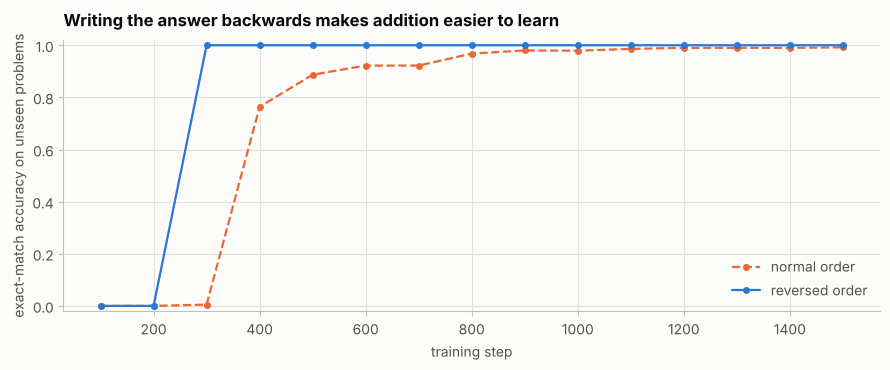

normal order    accuracy on all 5,000 test problems: 0.9926   (37 wrong)
reversed order  accuracy on all 5,000 test problems: 1.0000   (0 wrong)


In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for curve, label, color, dash in [(normal_curve, "normal order", PALETTE[1], "--"), (reversed_curve, "reversed order", PALETTE[0], "-")]:
    s, acc = zip(*curve)
    ax.plot(s, acc, color=color, linestyle=dash, marker="o", markersize=4, label=label)
ax.set_xlabel("training step")
ax.set_ylabel("exact-match accuracy on unseen problems")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Writing the answer backwards makes addition easier to learn")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

results = {"normal order": exact_accuracy(normal_model, False), "reversed order": exact_accuracy(reversed_model, True)}
for name, acc in results.items():
    print(f"{name:<15} accuracy on all 5,000 test problems: {acc:.4f}   ({round((1 - acc) * 5000)} wrong)")

Both curves show the sudden jump typical of learning an algorithm: almost nothing for a couple of hundred steps, then a rapid rise once the model "gets it". After that they differ. The reversed model jumps straight to perfect and stays there. The normal-order model jumps later and less far, then spends the rest of training slowly closing the last few percent, and still makes mistakes at the end.

Both models are scored on problems they never saw, out of 10 billion possible ones, so neither is remembering answers. They've learnt a procedure. The reversed model just has a much easier procedure to learn, because the order in which it writes matches the order in which the answer can be worked out.

## 5. Which sums are hard?

Writing the answer from the left, the hard part is knowing whether a **carry is coming**. To write the thousands digit of 30766 + 12231, you need to know whether the hundreds column sends a carry. Its digits add up to 9, so that depends on whether the tens column sends one; the tens also add up to 9, so it depends on the units. A run of columns whose digits add up to **exactly 9** passes a carry straight through, so to write the digit on its left you have to look past the whole run. (Columns adding up to 10 or more always carry, and 8 or less never do, whatever happens further right.)

Let's measure, for each problem, the **longest run of columns adding up to 9**. Long runs are rare in random problems (each column adds up to 9 only one time in ten), so we build a separate test set with a few hundred problems for each run length, again never used in training.

In [9]:
def column_digits(n):
    return [(n // 10 ** i) % 10 for i in range(N_DIGITS)]          # units first


def longest_nines_run(a, b):
    run = longest = torch.zeros_like(a)
    for da, db in zip(column_digits(a), column_digits(b)):
        run = (run + 1) * (da + db == 9).long()                       # grows while columns add up to 9, resets otherwise
        longest = torch.maximum(longest, run)
    return longest


g = torch.Generator().manual_seed(7)
pool_a, pool_b = [], []
for length in range(N_DIGITS + 1):
    a = torch.randint(LIMIT, (3000,), generator=g)
    b = torch.randint(LIMIT, (3000,), generator=g)
    first = torch.randint(N_DIGITS - length + 1, (3000,), generator=g)        # where the run of 9s starts
    for i in range(N_DIGITS):
        in_run = (first <= i) & (i < first + length)
        b_digit = torch.where(in_run, 9 - (a // 10 ** i) % 10, (b // 10 ** i) % 10)
        b = b - ((b // 10 ** i) % 10) * 10 ** i + b_digit * 10 ** i
    pool_a.append(a)
    pool_b.append(b)
pool_a, pool_b = torch.cat(pool_a), torch.cat(pool_b)
fresh = torch.tensor([k not in test_keys for k in (pool_a * LIMIT + pool_b).tolist()])
pool_a, pool_b = pool_a[fresh], pool_b[fresh]
runs = longest_nines_run(pool_a, pool_b)

print(f"{'longest run of 9s':>18}{'problems':>10}{'normal':>9}{'reversed':>10}")
for length in range(N_DIGITS + 1):
    idx = torch.nonzero(runs == length).flatten()[:500]
    row = []
    for model, reverse in [(normal_model, False), (reversed_model, True)]:
        problems = encode_sums(pool_a[idx], pool_b[idx], reverse)
        row.append((solve(model, problems) == problems[:, ANSWER_START:]).all(dim=1).float().mean().item())
    print(f"{length:>18}{len(idx):>10}{row[0]:>9.3f}{row[1]:>10.3f}")

 longest run of 9s  problems   normal  reversed


                 0       500    1.000     1.000


                 1       500    0.996     1.000


                 2       500    0.790     1.000


                 3       500    0.532     1.000


                 4       500    0.380     1.000


                 5       500    0.372     1.000


For the normal-order model, accuracy falls as the runs of 9s get longer: the longer the run, the further it has to look ahead, without writing anything down, before it can commit to a digit. The reversed model handles every run length about equally well. It never has to look ahead: by the time it reaches a column, it has already written the digit to the right and knows whether there was a carry.

Here are some of the normal-order model's mistakes on the random test set:

In [10]:
problems = encode_sums(test_a, test_b, reverse=False)
answers = solve(normal_model, problems)
wrong = torch.nonzero((answers != problems[:, ANSWER_START:]).any(dim=1)).flatten()
test_runs = longest_nines_run(test_a, test_b)
for i in wrong[:10].tolist():
    a, b = test_a[i].item(), test_b[i].item()
    said = int(show(answers[i]))
    print(f"{a:05d} + {b:05d} = {a + b:06d}, model said {said:06d}   (off by {said - (a + b):+,}; longest run of 9s: {test_runs[i].item()})")
if len(wrong):
    share = (test_runs[wrong] >= 2).float().mean().item()
    print(f"\n{share:.0%} of the mistakes have a run of two or more 9s, against {(test_runs >= 2).float().mean():.0%} of all test problems")

66116 + 83882 = 149998, model said 159998   (off by +10,000; longest run of 9s: 3)
30766 + 12231 = 042997, model said 043997   (off by +1,000; longest run of 9s: 2)
86587 + 46410 = 132997, model said 133997   (off by +1,000; longest run of 9s: 2)
45551 + 94408 = 139959, model said 149959   (off by +10,000; longest run of 9s: 2)
31933 + 32063 = 063996, model said 064996   (off by +1,000; longest run of 9s: 2)
45270 + 64817 = 110087, model said 100087   (off by -10,000; longest run of 9s: 1)
87184 + 52816 = 140000, model said 130000   (off by -10,000; longest run of 9s: 3)
83280 + 26808 = 110088, model said 100088   (off by -10,000; longest run of 9s: 1)
28119 + 64882 = 093001, model said 092001   (off by -1,000; longest run of 9s: 2)
62900 + 59097 = 121997, model said 122997   (off by +1,000; longest run of 9s: 2)

86% of the mistakes have a run of two or more 9s, against 4% of all test problems


The mistakes are typically off by exactly a power of ten: one digit wrong because the model guessed wrong about whether a carry was on its way. And they're concentrated in the problems with runs of 9s. The model has learnt to add very well; what it gets wrong is precisely the part that requires looking several steps ahead before writing anything.

This is a small version of something seen in large language models. They do better at arithmetic, and at reasoning in general, when they're allowed to write intermediate steps before the answer (the idea behind "chain of thought"), because then each token they write only needs a small step of work, just as each reversed digit does here.

## 6. Inside the reversed model

How does the reversed model add? Its attention weights give a hint. Below, for each answer digit the model writes, we show how much attention the heads in its **first block** pay to each position of the question, averaged over 1,000 test problems. Rows are the answer digits in the order they're written (units first); columns are the positions of the question.

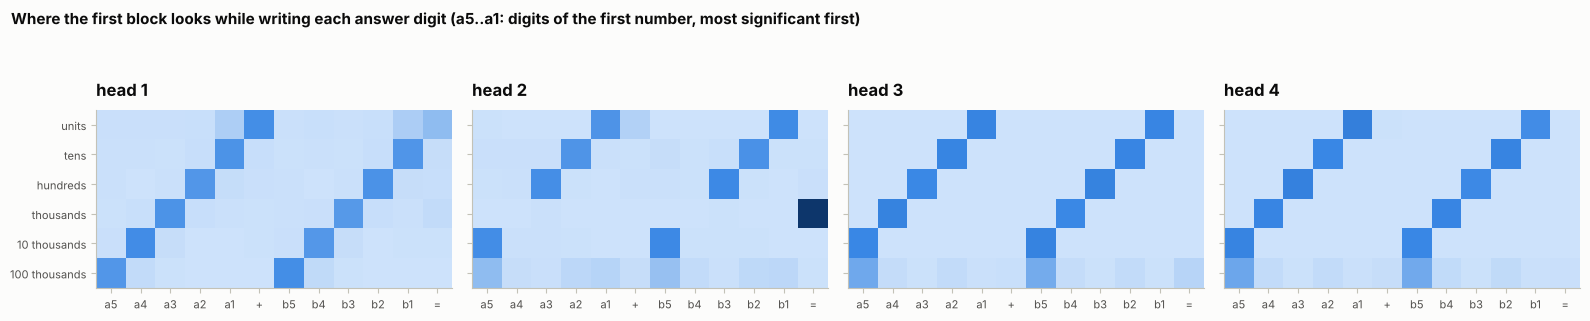

share of attention, averaged over the units to the 10 thousands:
head 1: on the same column 0.07   on the column to its right 0.84
head 2: on the same column 0.72   on the column to its right 0.01
head 3: on the same column 1.00   on the column to its right 0.00
head 4: on the same column 0.99   on the column to its right 0.00


In [11]:
problems = encode_sums(test_a[:1000], test_b[:1000], reverse=True).to(device)
reversed_model.eval()
with torch.no_grad():
    x = reversed_model.token_emb(problems[:, :-1]) + reversed_model.pos_emb(torch.arange(SEQ_LEN - 1, device=device))
    _, weights = reversed_model.blocks[0].attn(reversed_model.blocks[0].ln1(x), return_weights=True)
# the prediction of answer digit j is made at position ANSWER_START - 1 + j
rows = weights[:, :, ANSWER_START - 1:ANSWER_START - 1 + N_DIGITS + 1, :ANSWER_START].mean(dim=0).cpu()    # (heads, 6, 12)

columns = [f"a{i}" for i in range(N_DIGITS, 0, -1)] + ["+"] + [f"b{i}" for i in range(N_DIGITS, 0, -1)] + ["="]
row_labels = ["units", "tens", "hundreds", "thousands", "10 thousands", "100 thousands"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for h, ax in enumerate(axes):
    ax.imshow(rows[h], cmap="course_blues", vmin=0, vmax=rows.max())
    ax.set_xticks(range(len(columns)), columns, fontsize=8)
    ax.set_yticks(range(len(row_labels)), row_labels if h == 0 else [""] * len(row_labels), fontsize=8)
    ax.grid(False)
    ax.set_title(f"head {h + 1}")
fig.suptitle("Where the first block looks while writing each answer digit (a5..a1: digits of the first number, most significant first)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

def column_positions(j):
    """Positions of the j-th column from the right (0 = units) in the question: one digit of a, one of b."""
    return [N_DIGITS - 1 - j, 2 * N_DIGITS - j]


print("share of attention, averaged over the units to the 10 thousands:")
for h in range(4):
    same = np.mean([rows[h, j, column_positions(j)].sum().item() for j in range(N_DIGITS)])
    previous = np.mean([rows[h, j, column_positions(j - 1)].sum().item() for j in range(1, N_DIGITS)])
    print(f"head {h + 1}: on the same column {same:.2f}   on the column to its right {previous:.2f}")

The pattern is strikingly clean. Each diagonal line is a head lining up answer digits with question digits: while writing the units it looks at `a1` and `b1`, while writing the tens at `a2` and `b2`, and so on. Most heads split their attention between **the matching digit of both numbers**, which is exactly the pair of digits that has to be added for that column. A head whose diagonals sit one place to the left is looking at the **column to the right** instead, the one the carry comes from (for the units, which have no such column, it rests on the `+` and `=` signs). The second block and the MLPs then combine what was gathered into the digit.

Nobody told the model that addition works column by column. It discovered that from examples, because that's what predicting the next digit requires.

## 7. Saving the adder

The reversed model is the one to keep. Saving it works as in Module 17; the `add` function hides the reversed digits, so the person using it never needs to know.

In [12]:
Path("work").mkdir(exist_ok=True)
torch.save({"state_dict": reversed_model.state_dict(), "n_digits": N_DIGITS}, "work/adder.pt")

saved = torch.load("work/adder.pt", weights_only=True)
adder = GPT(len(VOCAB), SEQ_LEN - 1).to(device)
adder.load_state_dict(saved["state_dict"])


def add(a, b, model=adder):
    if not (0 <= a < LIMIT and 0 <= b < LIMIT):
        raise ValueError(f"this model only adds whole numbers from 0 to {LIMIT - 1:,}")
    problem = encode_sums(torch.tensor([a]), torch.tensor([b]), reverse=True)
    reversed_answer = solve(model, problem)[0]
    return int(show(reversed_answer.flip(dims=[0])))


for a, b in [(12345, 67890), (99999, 1), (31415, 27182), (50000, 49999), (0, 0)]:
    result = add(a, b)
    print(f"{a} + {b} = {result}   {'correct' if result == a + b else 'WRONG, should be ' + str(a + b)}")
print(f"\nthe loaded model's accuracy on all 5,000 test problems: {exact_accuracy(adder, True):.4f}")

12345 + 67890 = 80235   correct
99999 + 1 = 100000   correct
31415 + 27182 = 58597   correct
50000 + 49999 = 99999   correct
0 + 0 = 0   correct



the loaded model's accuracy on all 5,000 test problems: 1.0000


## What we learned

- **A transformer can learn an algorithm from examples.** Tested on problems it never saw, out of 10 billion possible, both models are far beyond memorising.
- **The format of the data matters enormously.** The same model, trained the same way, learnt much faster and better when the answer was written in the order it can be computed. Tokenisation and formatting choices, invisible in most discussions of language models, shape what they find easy and hard.
- **Errors cluster where the work is hardest:** long carry chains, where the normal-order model would have to plan many steps ahead.
- **Attention patterns can be read.** In the reversed model, heads line up each answer digit with the matching digits of the numbers.
- **Writing intermediate steps helps**, for this little model and for large ones.

**Know the limits.** This model only adds numbers of up to 5 digits: its position table has 17 rows, and it has never seen a 6-digit number. Making transformers generalise to longer numbers than they were trained on is an active research topic, and one more reason large models are given calculators and code to run instead of doing long arithmetic in their heads.

**Try next:**

- Train both models for longer (3,000 steps). Does the normal-order model reach the reversed one?
- Try subtraction or multiplication. Multiplication of two 3-digit numbers is much harder; does reversing still help?
- Add a "scratchpad": write the column sums or carries before the answer, and see whether the normal-order model improves.

Next, Module 20 moves from building transformers to using the large pretrained ones: prompting, embeddings, retrieval and fine-tuning.